# Homework 1 — Regression

This homework is focused on a complete regression workflow: data preparation, model training, hyperparameter tuning, model selection, and final evaluation.

The homework is worth **15 points**.

- Deadlines and submission rules are listed at [https://courses.fit.cvut.cz/BIE-ML1/homeworks/index.html](https://courses.fit.cvut.cz/BIE-ML1/homeworks/index.html).
- Submit the completed notebook together with the output file `results.csv`.
- Use Markdown cells to briefly explain important decisions and results. Keep the notebook clear and reasonably concise.
- If you submit the homework after the first deadline but before the final deadline, you will receive a penalty of **-7 points**. Submissions after the final deadline will receive no points.

> **The homework is intentionally open-ended in several places. Choosing an appropriate way to solve the individual parts of the task is part of the assignment. Your decisions should be reasonable and briefly justified.**

> **A complete solution should demonstrate sufficient experimentation and understanding of the methods.**

## Data

Your task is to predict the selling price of used cars.

You are given:

- `data.csv` — data containing the target variable `Price`,
- `evaluation.csv` — previously unseen data without `Price`, used for final evaluation.

### Variables

- `ID` — record identifier
- `Make` — car manufacturer
- `Price` — selling price; **target variable**
- `Year` — year of manufacture
- `Kilometer` — mileage in kilometres
- `Fuel Type` — fuel type
- `Transmission` — transmission type
- `Location` — city where the car was sold
- `Color` — car colour
- `Owner` — ownership information
- `Seller Type` — type of seller
- `Engine` — engine displacement
- `Drivetrain` — driven wheels
- `Length` — vehicle length in mm
- `Width` — vehicle width in mm
- `Height` — vehicle height in mm
- `Seating Capacity` — number of seats
- `Fuel Tank Capacity` — fuel tank capacity in litres

Some variables are numerical, some are categorical, some require a simple transformation, and some values are missing.

## Tasks
* Load the data from `data.csv` into the notebook. Split the dataset appropriately into subsets that will be used for model training (training set), model comparison (validation set), and subsequent estimation of the performance of the final model (test set).

* Perform basic data preprocessing:
  * Inspect the individual features and transform them into a suitable form for use with the selected regression models. For example, extract the numerical value from the `Engine` feature.
  * Handle missing values using some simple approach (e.g. replace them with a selected constant or another simple value). *Be careful about methodological errors!*
  * You may also use visualizations where appropriate. Briefly but sufficiently comment on your choices and results.

* Apply **linear regression**, **ridge regression**, and one of the following regression models: **decision tree** or **k-nearest neighbours**. For each model, as appropriate:
  * Comment on the suitability of the model for this type of problem.
  * Experiment with feature scaling (standardization / min-max scaling) if you expect it to have a beneficial effect on the model.
  * Select the main hyperparameter(s) to tune, where applicable, and find suitable values with respect to MSE.
  * For the model with the best hyperparameter values on the validation set, report its MSE.
  * Briefly comment on the obtained results.

* From all the considered models, select the final model and correctly estimate the prediction error, measured by RMSE (i.e. the square root of MSE), that you can expect on new data that have not been available to you so far. *Be careful about methodological errors!*

* Finally, load the evaluation data from `evaluation.csv` and use your final model to compute predictions for these data. Create a file `results.csv` containing the predictions in a column named **Price** and the corresponding identifiers in a column named **ID** (keep these column names exactly). Submit this file together with the notebook.

  An example of the first few rows of `results.csv` (with generally different values of `Price`) is:

```text
ID,Price
548,450000
879,680000
...
```


Store `results.csv` next to this notebook and submit both files.

## What should be explained in the notebook?

You do not need to write long descriptions. Briefly explain:

1. which variables you removed, if any, and why,
2. how you handled categorical and missing values,
3. when and why you used scaling,
4. which hyperparameter values you tried and which were selected,
5. why you selected the final model,
6. what test RMSE you obtained and what it means.


# The imports

In [41]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import ParameterGrid
import seaborn as sns

# Data preparation and processing
## Data preparation
1. Data was loaded into Pandas DataFrame and using the `na_values` parameter I tried to unify the representation of missing value into a standart one.
2. The `ID` feature was dropped as it doesn't carry any useful information for the model and could cause overfitting in some cases.
3. The `Engine` feature was transformed into a float by using RegEx. Float was used because it can carry the NaN, meanwhile int cannot.
4. The data was split into the Xtrain, Xval, and Xtest sets using the 60/20/20 division.

In [42]:
# 1. Data preparation
# 1.1 Load the data from `data.csv` into the notebook.
df = pd.read_csv('data.csv', na_values=["", "?", "N/A", "n/a", "NA", "null", "None", "-", "--", "nan"])
df = df.drop(["ID"], axis=1)
df['Volume'] = df['Length'] * df['Width'] * df['Height']

# Convert Engine to integer
df["Engine"] = df["Engine"].str.extract(r"(\d+)", expand=False).astype(float)

# 1.2 Split the dataset into training set, validation set, test set.
seed = 123

Xdata = df.drop(columns='Price')
ydata = df.Price

Xtrain, Xtemp, ytrain, ytemp = train_test_split(
    Xdata, ydata,
    test_size = 0.4,
    random_state=seed
)

Xval, Xtest, yval, ytest = train_test_split(
    Xtemp, ytemp,
    test_size = 0.5,
    random_state=seed
)

print("train:", Xtrain.shape, ytrain.shape)
print("validation:", Xval.shape, yval.shape)
print("test:", Xtest.shape, ytest.shape)

train: (1009, 17) (1009,)
validation: (337, 17) (337,)
test: (337, 17) (337,)


## Data Processing
1. First think first I had to deal with the missing values. Removing the data wasn't an option as in in that case lots of the training data would be left out. So after exploring the features that contain missing values I decided to act as following: if the value is numerical it would be imputed using median, and for the text features would be added a new category "Unknown".
2. One-Hot encoder was used with nominal features, and transmission (having only Manual and Automatic from my observations) is now in binary.
3. After inspecting the `Owner` feature I found it being ordinal from its mean, so for it I used OrdinalEncoder.
4. And finally for the `Make` and `Location` I used TargetEncoder. I did't want to encode them using the One-Hot encoder because of the amount of features they would add that are almost always zeros. So I used TargetEncoder instead to link Location and Car brand to the avg price.

In [ ]:
# 2. Basic data preprocessing
# 2.1 Handle missing values using some simple approach ->  You need imputation that is fit on train, for example SimpleImputer (median for numeric columns, most-frequent or an "Unknown" category for Drivetrain)
# 2.2 Inspect the individual features and transform them into a suitable form for use with the selected regression models.

# What I want to try:
# 1. Remove columns like: Color, Volume, Location
# 2. Transform target to log(Price)
# 3. Encoding
#     - Make: Target (current) vs. One-hot
#     - Owner: Ordinal (current) vs One-hot
#     - Drivetrain: One-hot (current) vs Ordinal

owner_order = [['4 or More', 'Fourth', 'Third', 'Second', 'First', 'UnRegistered Car']]
const = SimpleImputer(strategy="constant", fill_value="Unknown")

pre = ColumnTransformer([
    ("Numeric imputer", SimpleImputer(strategy="median"), ['Engine', 'Fuel Tank Capacity']),
    ("Nominal One-hot", Pipeline([("Constant imputaion", const), ("One-hot encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.int8))]), ['Drivetrain', 'Fuel Type', 'Color', 'Seller Type']),
    ("Binary Encoding of Transmission", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False, dtype=np.int8), ['Transmission']),
    ("Ordinal Encoding", OrdinalEncoder(categories=owner_order, handle_unknown="use_encoded_value", unknown_value=-1), ['Owner']),
    ("Target Encoding", TargetEncoder(smooth="auto", target_type="continuous", cv=KFold(5, shuffle=True, random_state=seed)), ['Location', 'Make']),
], remainder="passthrough")

pre.set_output(transform="pandas")
Xtrain = pre.fit_transform(Xtrain, ytrain)
Xval = pre.transform(Xval)
Xtest = pre.transform(Xtest)

pd.concat([Xtrain, Xval, Xtest]).columns

Index(['Numeric imputer__Engine', 'Numeric imputer__Fuel Tank Capacity',
       'Nominal One-hot__Drivetrain_AWD', 'Nominal One-hot__Drivetrain_FWD',
       'Nominal One-hot__Drivetrain_RWD',
       'Nominal One-hot__Drivetrain_Unknown', 'Nominal One-hot__Fuel Type_CNG',
       'Nominal One-hot__Fuel Type_CNG + CNG',
       'Nominal One-hot__Fuel Type_Diesel',
       'Nominal One-hot__Fuel Type_Electric',
       'Nominal One-hot__Fuel Type_Hybrid', 'Nominal One-hot__Fuel Type_LPG',
       'Nominal One-hot__Fuel Type_Petrol', 'Nominal One-hot__Color_Black',
       'Nominal One-hot__Color_Blue', 'Nominal One-hot__Color_Bronze',
       'Nominal One-hot__Color_Brown', 'Nominal One-hot__Color_Gold',
       'Nominal One-hot__Color_Green', 'Nominal One-hot__Color_Grey',
       'Nominal One-hot__Color_Maroon', 'Nominal One-hot__Color_Orange',
       'Nominal One-hot__Color_Others', 'Nominal One-hot__Color_Purple',
       'Nominal One-hot__Color_Red', 'Nominal One-hot__Color_Silver',
       'No

# Linear Regression

## Suitability of the model for this type of problem
Predicting the car price is one of the typical examples of the problem that Linear Regression model can solve. It is a good choice of model as long as there is an actual linear dependance between input features and target and as long the the training data represents the actual data well (e.g training data includes all sort of cars and not only luxary).

## Obtained results
Best hyperparameters and MSE

RMSE: 946839.8250474571
R2 score: 0.6978951391971574


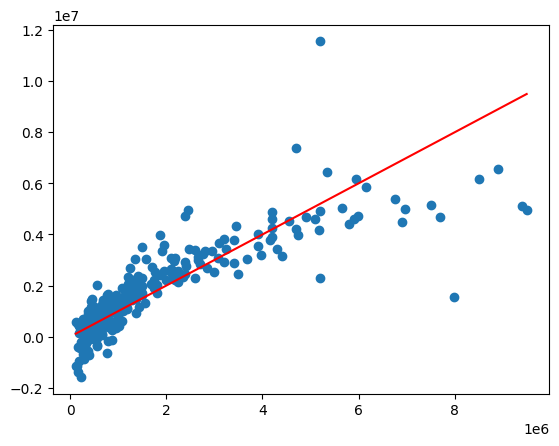

In [ ]:
# 3.2 Experiment with feature scaling
# 3.3 Choose hyperparameters to tune and find suitable values with respect to MSE.
scaler = StandardScaler()

Xtrain_scaled = scaler.fit_transform(Xtrain)
Xval_scaled = scaler.transform(Xval)
    
clf = LinearRegression()
clf.fit(Xtrain_scaled, ytrain)
Y_predict_val = clf.predict(Xval_scaled)

print(f"RMSE: {root_mean_squared_error(y_true=yval, y_pred=Y_predict_val)}")
print(f"R2 score: {r2_score(yval, Y_predict_val)}")

plt.scatter(yval, Y_predict_val)
plt.plot([yval.min(), yval.max()], [yval.min(), yval.max()], 'r')
plt.show()

In [45]:


# 4. Ridge regression
# 4.1 Comment on the suitability of the model for this type of problem.
# 4.2 Experiment with feature scaling
# 4.3 Choose hyperparameters to tune and find suitable values with respect to MSE.
# 4.4 For the model with the best hyperparameter values on the validation set report its MSE.
# 4.5 Briefly comment on the obtained results.

# 5. Decision tree / k-nearest neighbours
# 5.1 Comment on the suitability of the model for this type of problem.
# 5.2 Experiment with feature scaling
# 5.3 Choose hyperparameters to tune and find suitable values with respect to MSE.
# 5.4 For the model with the best hyperparameter values on the validation set report its MSE.
# 5.5 Briefly comment on the obtained results.

# 6. From all the considered models, select the final model and correctly estimate the prediction error, measured by RMSE (i.e. the square root of MSE), that you can expect on new data that have not been available to you so far. *Be careful about methodological errors!*

# 7. Final evaluation
# 7.1 Load the evaluation data from `evaluation.csv`
# 7.2 Use your final model to compute predictions for these data.
# 7.3 Create a file `results.csv` containing the predictions in a column named **Price** and the corresponding identifiers in a column named **ID** (keep these column names exactly).
# 7.4 Submit this file together with the notebook.